In [1]:
import pandas as pd

df = pd.read_csv("/home/thinkpad/Documents/BrototypeStudying/paper_three/Paper3/data/unsupervised_customers.csv")

In [2]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(df)

In [4]:
from sklearn.decomposition import PCA

model = PCA(n_components=2)
x_pca = model.fit_transform(X_scaled)

print(model.explained_variance_ratio_.sum())

0.966162275665855


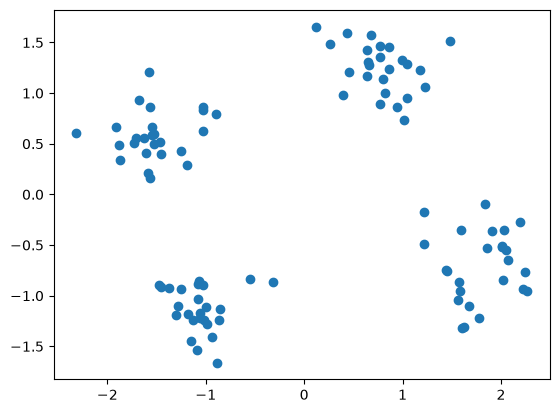

In [5]:
import matplotlib.pyplot as plt

plt.scatter(x_pca[:, 0], x_pca[:, 1])
plt.show()

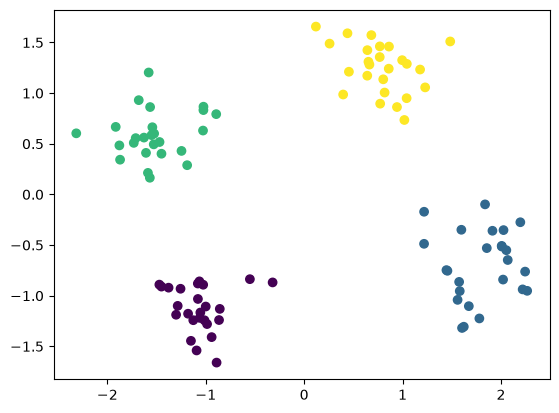

In [9]:
from sklearn.cluster import KMeans

model = KMeans(n_clusters=4, n_init=10, random_state=42)

model.fit(x_pca)
labels = model.predict(x_pca)
df["clusters"] = model.labels_

plt.scatter(x_pca[:, 0], x_pca[:, 1], c=labels)

In [10]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("/home/thinkpad/Documents/BrototypeStudying/paper_three/Paper3/data/classification_students.csv")

x = df.drop(columns="passed")        # inputs: every column except the answer
y = df["passed"]                     # the answer (target)

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

print(x_train.shape, x_test.shape)  

(80, 6) (20, 6)


In [14]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics  import accuracy_score

kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

RandomForestClassifier
params = {
    "n_estimators":[50, 100, 150],
    "max_depth" : [2, 4, 6, 8, 10]
} 

rand = RandomizedSearchCV(RandomForestClassifier(random_state=42),params, n_iter=5, cv=kf, scoring="accuracy", random_state=42)

rand.fit(x_train, y_train)
print(rand.best_params_, rand.best_score_)

bestModel = rand.best_estimator_
print(bestModel.score(x_test, y_test))

{'n_estimators': 50, 'max_depth': 8} 0.725
0.75


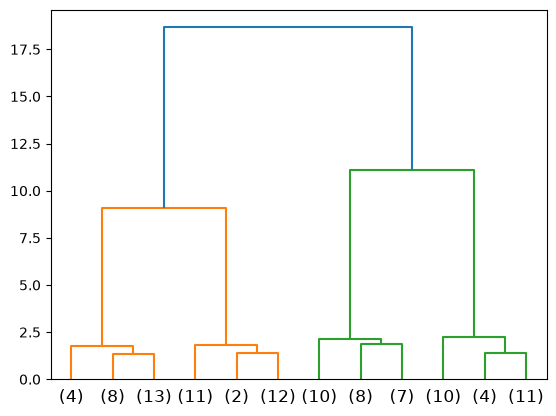

In [18]:
from scipy.cluster.hierarchy import dendrogram, linkage

Z = linkage(X_scaled, method="ward")
dendrogram(Z, truncate_mode="lastp", p=12)
plt.show()
